In [1]:
!pip install opencv-python matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


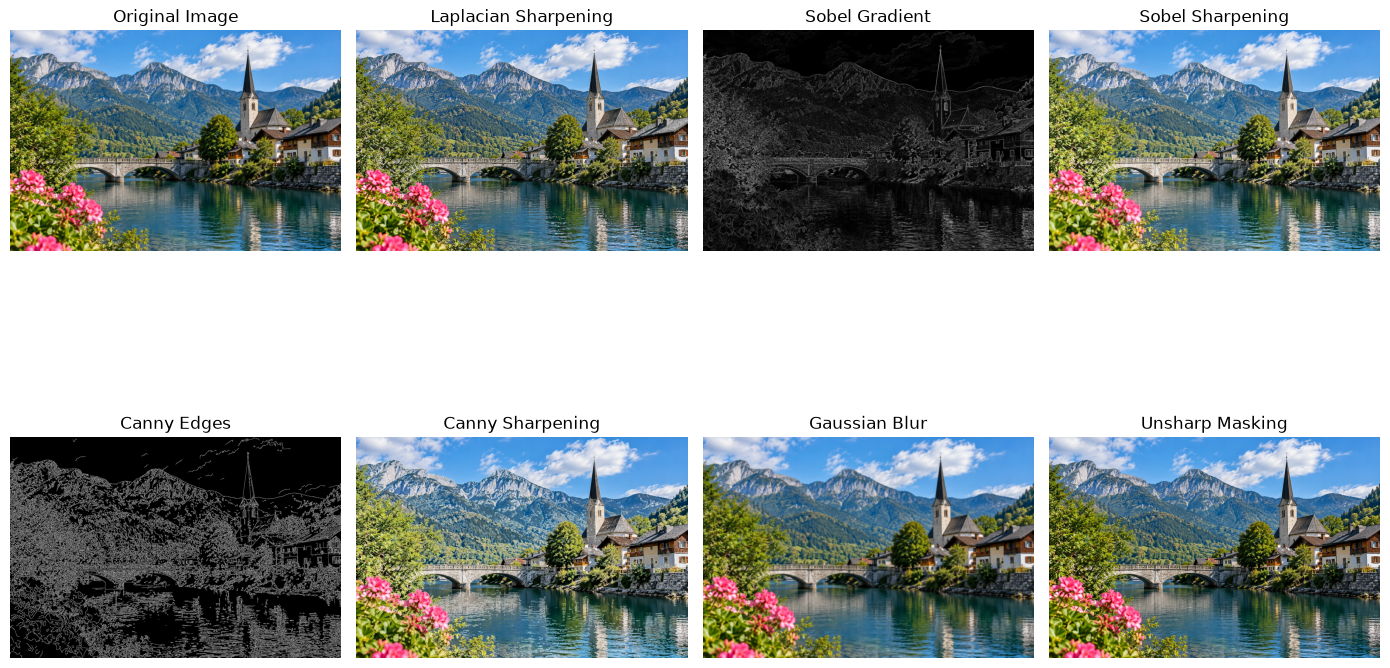

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("input7.png")

if img is None:
    print("Image not found")
else:
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 1. Laplacian Filter
    laplacian = cv2.Laplacian(img, cv2.CV_64F)
    laplacian = laplacian.astype(np.float32)

    sharpened_laplacian = cv2.addWeighted(
        img.astype(np.float32), 1.0,
        laplacian, -1.0, 0
    )
    sharpened_laplacian = cv2.convertScaleAbs(sharpened_laplacian)

    # 2. Sobel Gradient Operator
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

    magnitude = cv2.magnitude(gx, gy)
    magnitude = cv2.normalize(
        magnitude, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    magnitude_color = cv2.cvtColor(magnitude, cv2.COLOR_GRAY2BGR)
    sharpened_sobel = cv2.addWeighted(
        img, 1.0, magnitude_color, 0.5, 0
    )

    # 3. Canny Edge Detector
    edges = cv2.Canny(gray, 100, 200)
    edges_color = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

    sharpened_canny = cv2.addWeighted(
        img, 1.0, edges_color, 0.5, 0
    )

    # 4. Unsharp Masking
    blurred = cv2.GaussianBlur(img, (5, 5), 3)

    sharpened_unsharp = cv2.addWeighted(
        img, 1.5, blurred, -0.5, 0
    )

    # Display Results
    images = [
        ("Original Image", img),
        ("Laplacian Sharpening", sharpened_laplacian),
        ("Sobel Gradient", magnitude),
        ("Sobel Sharpening", sharpened_sobel),
        ("Canny Edges", edges),
        ("Canny Sharpening", sharpened_canny),
        ("Gaussian Blur", blurred),
        ("Unsharp Masking", sharpened_unsharp)
    ]

    plt.figure(figsize=(14, 10))

    for i, (title, image) in enumerate(images):
        plt.subplot(2, 4, i + 1)

        if len(image.shape) == 2:
            plt.imshow(image, cmap="gray")
        else:
            plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()
